In [9]:
import numpy as np
from matplotlib import pyplot as plt


In [10]:
def polygon_area(coords):
    coords = np.asarray(coords)
    x = coords[:, 0]
    y = coords[:, 1]

    return 0.5 * abs(
        np.dot(x, np.roll(y, -1)) -
        np.dot(y, np.roll(x, -1))
    )

# This is the shoelace formula for the area of the polygon given its vertex coordinates
# np.roll is a neat trick that lets this be vectorized instead of looped
# np.dot(x, np.roll(y, -1)) = SUM(x_i*y_(i+1)) and the same for the next, difference of them and their absolute value multiplied to 0.5


In [11]:
zfold = np.array([(-1/2,0),(-1/2,-1),(1/2,-1),(1/2,0)])
# an array of vertices - that of a square

times_v = np.array((0,1,1,2,2))/3
times_vp = np.array((0,0,1,1,0))/3

# this segment basically switches out the line segment for a square, this is what makes a boundary fractal

def nfold_square(n, fold_sign = 1,return_all=False, same_area=False):
    if n == 1:
        if return_all:
            return [zfold]
        return zfold

    z = nfold_square(n-1, fold_sign, return_all, same_area=False)
    if return_all:
        list = z
        z = z[-1].copy()

    nfold_stack = []
    for i in range(len(z)-1):
        v = z[i+1] - z[i]
        v_perp = np.array((v[1], -v[0])) * fold_sign
        nfold_stack.append(z[i] + np.outer(times_v,v) + np.outer(times_vp,v_perp))

    nfold_stack.append(z[-1])
    nfold_stack = np.vstack(nfold_stack)
    if return_all:
        list.append(nfold_stack)
        if same_area:
            return [g/np.sqrt(polygon_area(g)) for i, g in enumerate(list)]
        return list

    if same_area:
        nfold_stack *= 1/np.sqrt(polygon_area(nfold_stack))

    return nfold_stack

# walk 1/3 of the segment's length then step otu (perpendicularly) and walk the same amount, walk across the same 1/3rd amount, come back in the same amount and then finish the walk on teh orignal leftover 1/3rd of the segment

In [12]:
htri = np.sqrt(3)/2
# height of the triangle
zfold_tri = np.array([(-1/2,0),(0,-htri),(1/2,0)])

# A_triforce = lambda i: 2*(11/28-(1/7)*((2/9)**i))

times_v_tri  = np.array((0,1/3,1/2,2/3))
times_vp_tri = np.array((0,0,1,0))*htri/3

def nfold_triangle(n, fold_sign = 1, return_all=False, same_area=False):
    if n == 1:
        if return_all:
            return [zfold_tri]
        return zfold_tri

    z = nfold_triangle(n-1, fold_sign, return_all, same_area=False)
    if return_all:
        list = z
        z = z[-1].copy()

    nfold_stack = []
    for i in range(len(z)-1):
        v = z[i+1] - z[i]
        v_perp = np.array((v[1], -v[0]))*fold_sign
        nfold_stack.append(z[i] + np.outer(times_v_tri,v) + np.outer(times_vp_tri,v_perp))

    nfold_stack.append(z[-1])
    nfold_stack = np.vstack(nfold_stack)
    if return_all:
        list.append(nfold_stack)
        if same_area:
            return [g/np.sqrt(polygon_area(g)) for i, g in enumerate(list)]
        return list

    if same_area:
        nfold_stack *= 1/np.sqrt(polygon_area(nfold_stack))

    return nfold_stack


1.0
1.3333333333333333
1.5185185185185186


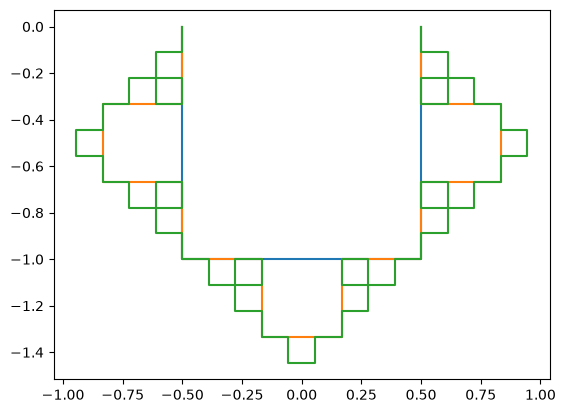

1.0
1.0
0.9999999999999989
1.0000000000000058


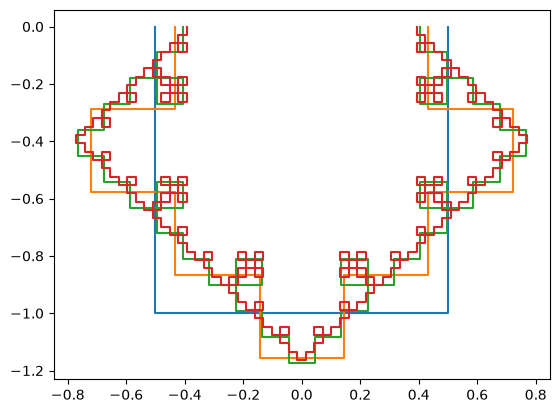

In [13]:
for g in nfold_square(3,return_all=True):
    plt.plot(*g.T)
    print(polygon_area(g))
plt.show()

for g in nfold_square(4,return_all=True,same_area=True):
    plt.plot(*g.T)
    print(polygon_area(g))


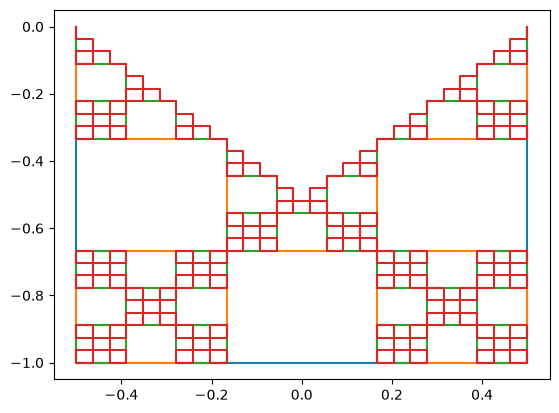

In [14]:
for g in nfold_square(4,return_all=True,fold_sign=-1):
    plt.plot(*g.T)
plt.show()



0.4330127018922193
0.529237746757157
0.5720044333637958
0.591011849633413
0.5994595901976842
0.603214141559514


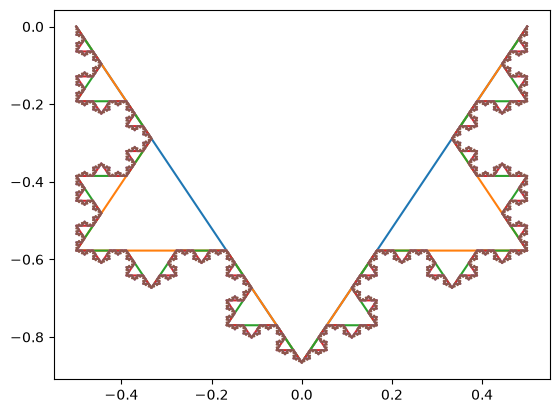

0.9999999999999999
1.0
1.0000000000000002
1.0000000000000004
0.9999999999999984
1.0000000000000668


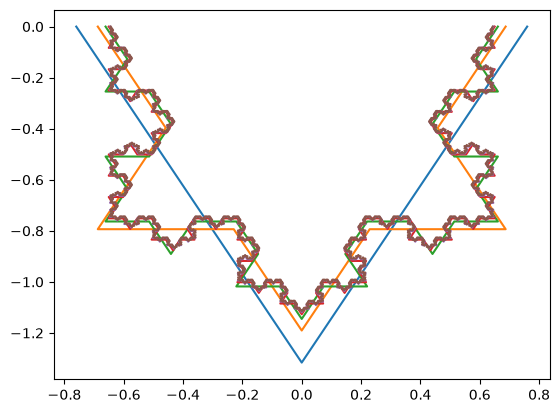

0.4330127018922193
0.3367876570272817
0.2940209704206428
0.2750135541510255
0.2665658135867516
0.2628112622248511


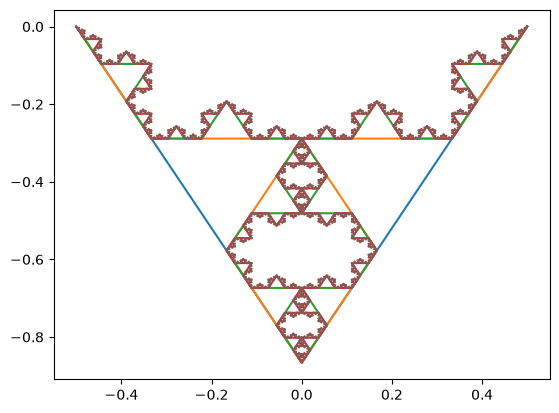

In [15]:
for g in nfold_triangle(6,return_all=True):
    plt.plot(*g.T)
    print(polygon_area(g))
plt.show()

for g in nfold_triangle(6,return_all=True,same_area=True):
    plt.plot(*g.T)
    print(polygon_area(g))
plt.show()

for g in nfold_triangle(6,return_all=True,fold_sign=-1):
    plt.plot(*g.T)
    print(polygon_area(g))
plt.show()


1.0
1.3333333333333333
1.5185185185185186


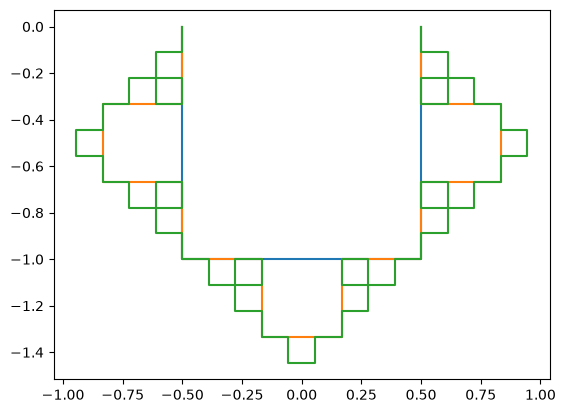

In [16]:
for g in nfold_square(3,return_all=True):
    plt.plot(*g.T)
    print(polygon_area(g))
plt.show()
